In [2]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load dataset directly

url = "https://raw.githubusercontent.com/rithwik00/Mall-Customer-Dataset/main/Mall_Customers.csv"

df = pd.read_csv(url)

# Display first five rows
print(df.head())

   CustomerID  Gender   Age   Annual Income (k$)   Spending Score (1-100)
0           1    Male    19                   15                       39
1           2    Male    21                   15                       81
2           3  Female    20                   16                        6
3           4  Female    23                   16                       77
4           5  Female    31                   17                       40


In [4]:
# Check dataset dimensions

print("Dataset Shape:", df.shape)

# Check dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   CustomerID               200 non-null    int64 
 1    Gender                  200 non-null    object
 2    Age                     200 non-null    int64 
 3    Annual Income (k$)      200 non-null    int64 
 4    Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Statistical Summary:
       CustomerID         Age   Annual Income (k$)   Spending Score (1-100)
count  200.000000  200.000000           200.000000               200.000000
mean   100.500000   38.850000            60.560000                50.200000
std     57.879185   13.969007            26.264721                25.823522
min      1.000000   18.000000            15.000000                 1.000000
25%     50.750000   28.7500

In [7]:
print(df.columns.tolist())

['CustomerID', ' Gender', ' Age', ' Annual Income (k$)', ' Spending Score (1-100)']


In [8]:
# Remove extra spaces from column names

df.columns = df.columns.str.strip()

# Display cleaned column names

print(df.columns.tolist())

['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [9]:
# Select important features

X = df[['Annual Income (k$)',
        'Spending Score (1-100)']]

print("Selected Features:")
print(X.head())

Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print(X_scaled[:5])

Feature scaling completed!
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


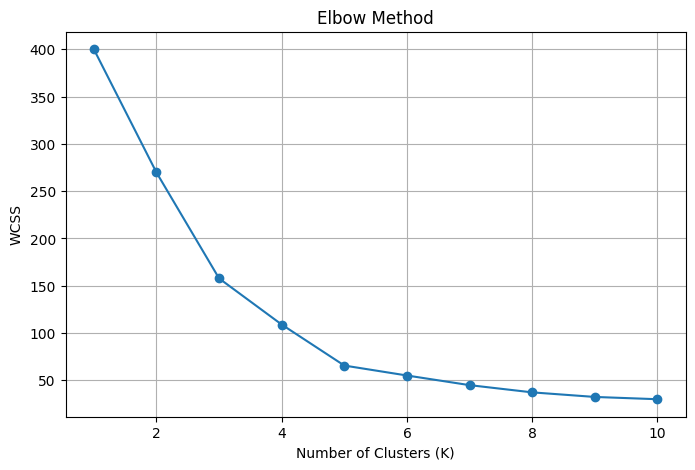

In [11]:
# Elbow Method to find optimal K

wcss = []

for i in range(1, 11):

    model = KMeans(
        n_clusters=i,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

# Plot Elbow Graph

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.grid(True)
plt.show()

In [12]:
# Calculate Silhouette Scores

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print("K =", k,
          "Silhouette Score =", round(score, 3))

K = 2 Silhouette Score = 0.321
K = 3 Silhouette Score = 0.467
K = 4 Silhouette Score = 0.494
K = 5 Silhouette Score = 0.555
K = 6 Silhouette Score = 0.54
K = 7 Silhouette Score = 0.528
K = 8 Silhouette Score = 0.455
K = 9 Silhouette Score = 0.457
K = 10 Silhouette Score = 0.443


In [13]:
# Create final K-Means model

kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    n_init=10,
    random_state=42
)

# Train model and assign clusters

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")

# Display customer clusters

print(df[['Annual Income (k$)',
          'Spending Score (1-100)',
          'Cluster']].head(10))

K-Means model trained successfully!
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4
5                  17                      76        2
6                  18                       6        4
7                  18                      94        2
8                  19                       3        4
9                  19                      72        2


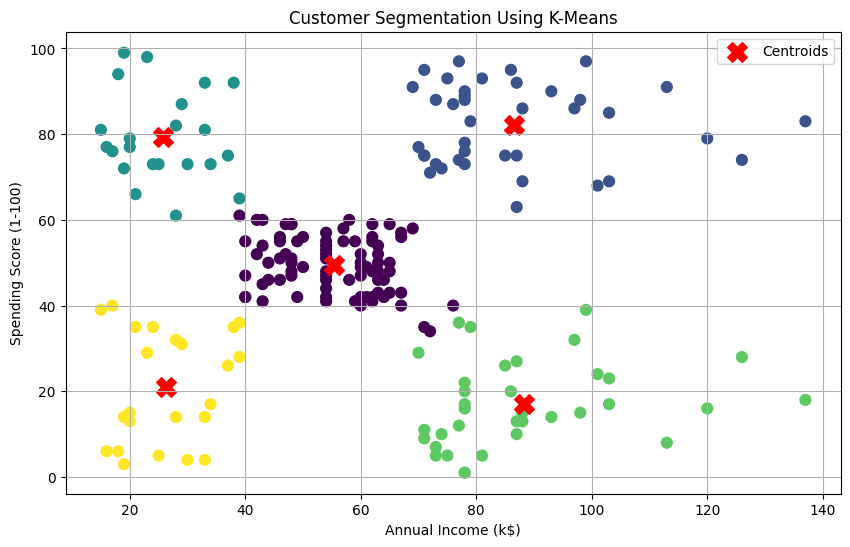

In [14]:
# Convert centroids to original scale

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Create cluster visualization

plt.figure(figsize=(10, 6))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

# Display centroids

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Count customers in each cluster

print("Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Calculate average income and spending

print("\nCluster Analysis:")

cluster_analysis = df.groupby('Cluster')[
    ['Annual Income (k$)',
     'Spending Score (1-100)']
].mean().round(2)

print(cluster_analysis)

Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster Analysis:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


In [16]:
final_score = silhouette_score(
    X_scaled,
    df['Cluster']
)

print("FINAL MODEL EVALUATION")
print("----------------------")
print("Number of Clusters:", 5)
print("Inertia (WCSS):", round(kmeans.inertia_, 2))
print("Silhouette Score:", round(final_score, 3))

FINAL MODEL EVALUATION
----------------------
Number of Clusters: 5
Inertia (WCSS): 65.57
Silhouette Score: 0.555


In [17]:
df.to_csv(
    'Customer_Segmentation_Results.csv',
    index=False
)

print("Results exported successfully!")

Results exported successfully!
